In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path
import seaborn as sns

data_dir = Path('../data')
cache_dir = data_dir / 'cache'
external_dir = data_dir / 'external'
processed_dir = data_dir / 'processed'

In [2]:
catalan_universities = {
    # Public (7)
    'Universitat de Barcelona': 'I71999127',
    'Universitat Autònoma de Barcelona': 'I123044942',
    'Universitat Politècnica de Catalunya': 'I9617848',
    'Universitat Pompeu Fabra': 'I170486558',
    'Universitat de Girona': 'I251424209',
    'Universitat de Lleida': 'I15766328',
    'Universitat Rovira i Virgili': 'I55952717',

    # Private (4)
    'Universitat Ramon Llull': 'I5593406',
    'Universitat de Vic-Universitat Central de Catalunya': 'I115304662',
    'Universitat Internacional de Catalunya': 'I3123915005',
    'Universitat Abat Oliba CEU': 'I2801339427',

    # Online (1)
    'Universitat Oberta de Catalunya': 'I138847295',
}

In [3]:
# Import complete df
afiliations = pd.read_parquet(external_dir / 'afiliations.parquet')

# Remove nan
afiliations = afiliations.dropna().reset_index(drop=True)

# Remove non catalan entrys
catalan_ids = list(catalan_universities.values())
afiliations = afiliations[afiliations['institution_id'].isin(catalan_ids)].reset_index(drop=True)

# Check df
afiliations

,work_openalex_id,author_id,institution_id
0,W1993308435,A5039571243,I71999127
1,W1993308435,A5064177201,I71999127
2,W2081673870,A5003175893,I55952717
3,W2081673870,A5067149287,I55952717
4,W2081673870,A5052548663,I55952717
...,...,...,...
696431,W1570020663,A5007639805,I9617848
696432,W1969633650,A5082431864,I123044942
696433,W1590121865,A5025955705,I71999127
696434,W1590121865,A5149372585,I71999127


In [4]:
# 1. Read data
works = pd.read_parquet(external_dir / 'works.parquet')
papers_cleaned_yr = pd.read_parquet(processed_dir / 'all_publications_enriched.parquet')
fields = pd.read_parquet(external_dir / 'fields.parquet')

# 2. Build lookups (one row per key)
id2doi = works.dropna(subset=['openalex_id']).drop_duplicates(subset='openalex_id').set_index('openalex_id')['doi']

doi2meta = (
    papers_cleaned_yr
    .dropna(subset=['doi'])
    .drop_duplicates(subset='doi', keep='first')
    .set_index('doi')[['year', 'field_name', 'domain_name']]
)

# 3. Attach doi -> year/field/domain to afiliations
afiliations = afiliations.copy()
afiliations['doi'] = afiliations['work_openalex_id'].map(id2doi)
afiliations = afiliations.merge(doi2meta, on='doi', how='left')
afiliations = afiliations.drop(columns='doi')

# 4. Cast year to nullable int
afiliations['year'] = afiliations['year'].astype('Int64')

afiliations

,work_openalex_id,author_id,institution_id,year,field_name,domain_name
0,W1993308435,A5039571243,I71999127,1987,Chemistry,Physical Sciences
1,W1993308435,A5064177201,I71999127,1987,Chemistry,Physical Sciences
2,W2081673870,A5003175893,I55952717,1987,Materials Science,Physical Sciences
3,W2081673870,A5067149287,I55952717,1987,Materials Science,Physical Sciences
4,W2081673870,A5052548663,I55952717,1987,Materials Science,Physical Sciences
...,...,...,...,...,...,...
696431,W1570020663,A5007639805,I9617848,2005,Computer Science,Physical Sciences
696432,W1969633650,A5082431864,I123044942,2005,Medicine,Health Sciences
696433,W1590121865,A5025955705,I71999127,2014,Psychology,Social Sciences
696434,W1590121865,A5149372585,I71999127,2014,Psychology,Social Sciences


In [5]:
# papers_inst = (
#     afiliations
#     .groupby('work_openalex_id')['institution_id']
#     .apply(lambda s: list(dict.fromkeys(s)))
#     .reset_index()
# )
# papers_inst = papers_inst.rename(columns={'institution_id': 'institutions'})
# papers_inst

In [11]:
from itertools import combinations

afil_recent = afiliations[
    (afiliations['year'] > 2016)
    & (afiliations['domain_name'] == 'Physical Sciences')
]

links = (
    afil_recent[['work_openalex_id', 'institution_id']]
    .drop_duplicates()
    .groupby('work_openalex_id')['institution_id']
    .apply(lambda s: list(combinations(sorted(s), 2)))
    .explode()
    .dropna()
    .value_counts()
    .reset_index(name='weight')
)

links[['institution_a', 'institution_b']] = pd.DataFrame(links['institution_id'].tolist(), index=links.index)
links = links.drop(columns='institution_id')

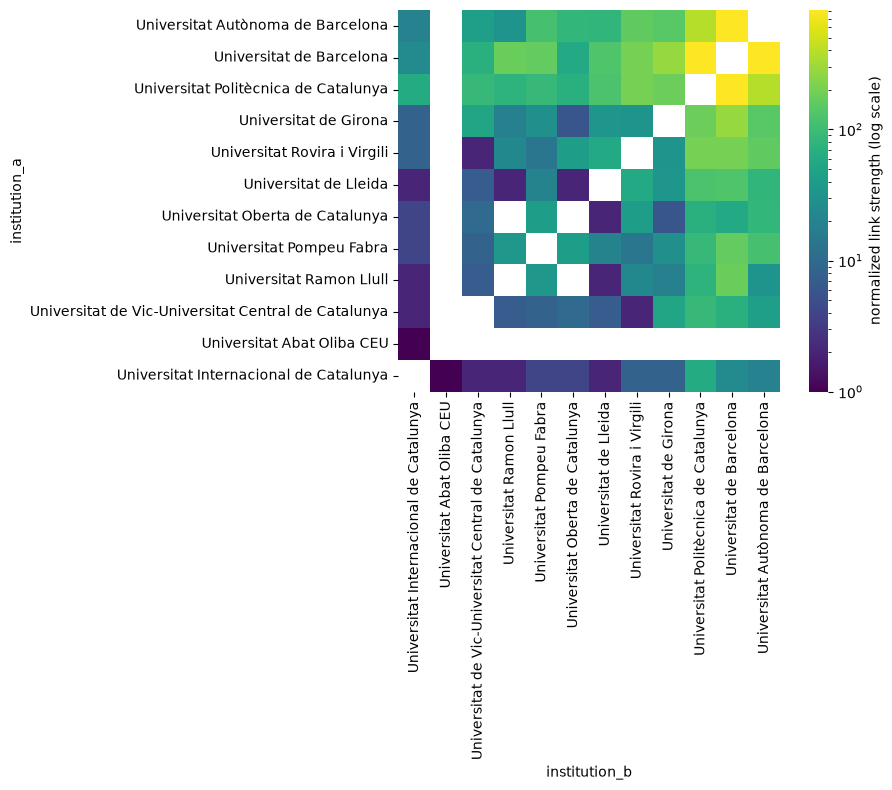

In [13]:
from matplotlib.colors import LogNorm
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import squareform

# Build matrix + normalized frac from links (so the cell is self-contained)
id2name = {v: k for k, v in catalan_universities.items() if v}
ordered_ids = [v for v in catalan_universities.values() if v]

matrix = links.pivot(index='institution_a', columns='institution_b', values='weight')
matrix = matrix.reindex(index=ordered_ids, columns=ordered_ids).fillna(0)
matrix = matrix.add(matrix.T, fill_value=0)

row_tot = matrix.sum(axis=1)
denom = np.sqrt(np.outer(row_tot, row_tot))
frac = matrix / denom

# ---- Cluster-order ----
sim = frac.fillna(0).to_numpy()
dist = 1 - sim
dist = (dist + dist.T) / 2
np.fill_diagonal(dist, 0)
Z = sch.linkage(squareform(dist, checks=False), method='average')
order = sch.leaves_list(Z)
ordered_ids_clust = [ordered_ids[i] for i in order]
matrix_c = matrix.loc[ordered_ids_clust, ordered_ids_clust]

# ---- Plot ----
heat_data = matrix_c.iloc[::-1].replace(0, np.nan)
labels_x = [id2name.get(i, i) for i in ordered_ids_clust]
labels_y = [id2name.get(i, i) for i in ordered_ids_clust[::-1]]

plt.figure(figsize=(10, 8))
sns.heatmap(
    heat_data,
    xticklabels=labels_x,
    yticklabels=labels_y,
    cmap='viridis',
    square=True,
    norm=LogNorm(vmin=heat_data.min().min(), vmax=heat_data.max().max()),
    cbar_kws={'label': 'normalized link strength (log scale)'}
)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

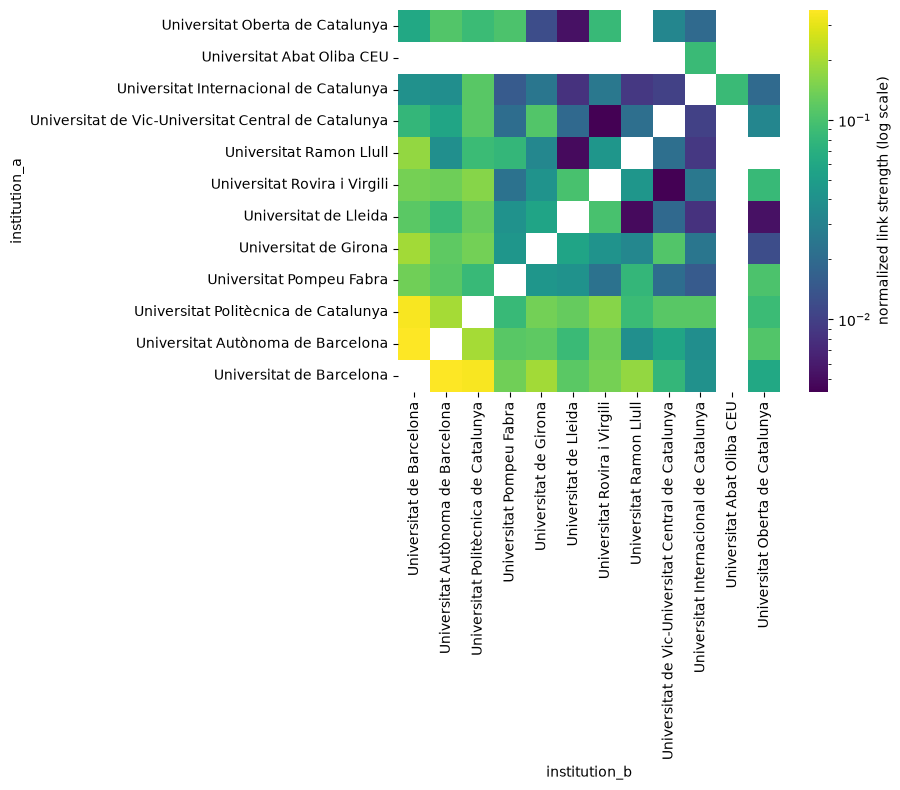

In [8]:
from matplotlib.colors import LogNorm
id2name = {v: k for k, v in catalan_universities.items() if v}
ordered_ids = [v for v in catalan_universities.values() if v]

matrix = links.pivot(index='institution_a', columns='institution_b', values='weight')
matrix = matrix.reindex(index=ordered_ids, columns=ordered_ids).fillna(0)
matrix = matrix.add(matrix.T, fill_value=0)

# Symmetric normalization (diagonal is already absent from links)
row_tot = matrix.sum(axis=1)
denom = np.sqrt(np.outer(row_tot, row_tot))
frac = matrix / denom

# Flip vertically for bottom-to-top y
matrix_plot = frac.iloc[::-1]
labels_x = [id2name.get(i, i) for i in matrix.index]
labels_y = [id2name.get(i, i) for i in matrix_plot.index]

frac_log = matrix_plot.replace(0, np.nan)

plt.figure(figsize=(10, 8))
sns.heatmap(
    frac_log,
    xticklabels=labels_x,
    yticklabels=labels_y,
    cmap='viridis',
    square=True,
    norm=LogNorm(vmin=frac_log.min().min(), vmax=frac_log.max().max()),
    cbar_kws={'label': 'normalized link strength (log scale)'}
)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()